In [58]:
# importo las librerias necesarias
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score


In [59]:
df_ent = pd.read_csv("../data/processed/pedidos_modelo.csv")
print(df_ent.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_state', 'customer_city', 'n_items', 'precio_total', 'flete_total', 'n_vendedores', 'peso_total_g', 'categoria', 'estado_vendedor', 'tarde', 'tarde_dia', 'mismo_estado', 'dias_prometidos', 'tramo_plazo', 'q_dias', 'peso_grupo', 'flete_grupo']


In [60]:
# Variables y target 

num_cols = ["dias_prometidos", "peso_total_g", "flete_total"]
cat_cols = ["customer_state", "estado_vendedor", "categoria"]
bin_cols = ["mismo_estado"]

X = df_ent[num_cols + cat_cols + bin_cols].copy()
y = df_ent["tarde_dia"].astype(int)
print(num_cols)
print(cat_cols)
print(bin_cols)

['dias_prometidos', 'peso_total_g', 'flete_total']
['customer_state', 'estado_vendedor', 'categoria']
['mismo_estado']


In [61]:
# Los 22 pesos en 0 son datos faltantes: los paso a NaN para imputarlos dentro del pipeline
X.loc[X["peso_total_g"] == 0, "peso_total_g"] = np.nan
X["mismo_estado"] = X["mismo_estado"].astype(int)

In [62]:
# Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("% tarde train:", round(y_train.mean() * 100, 2), "| test:", round(y_test.mean() * 100, 2))


(77176, 7) (19294, 7)
% tarde train: 6.77 | test: 6.77


In [63]:
# Baseline: siempre predice "a tiempo"
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)
proba = dummy.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96     17987
           1       0.00      0.00      0.00      1307

    accuracy                           0.93     19294
   macro avg       0.47      0.50      0.48     19294
weighted avg       0.87      0.93      0.90     19294

ROC-AUC: 0.5
PR-AUC : 0.068


In [64]:
# Preprocesamiento y primer pipeline 

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Numericas: rellenar faltantes con la mediana (los 22 pesos en NaN) y escalar
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categoricas: rellenar faltantes y pasar a columnas 0/1.
# min_frequency=100 agrupa las categorias con menos de 100 pedidos en "infrequent"
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="desconocido")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)),
])

# Une todo: cada grupo de columnas con su tratamiento; mismo_estado (0/1) pasa tal cual
preprocesador = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("bin", "passthrough", bin_cols),
], sparse_threshold=0)

# Pipeline completo: preprocesar + modelo
pipe_lr = Pipeline([
    ("prep", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

pipe_lr.fit(X_train, y_train)

pred = pipe_lr.predict(X_test)
proba = pipe_lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.96      0.67      0.79     17987
           1       0.12      0.63      0.20      1307

    accuracy                           0.67     19294
   macro avg       0.54      0.65      0.50     19294
weighted avg       0.90      0.67      0.75     19294

ROC-AUC: 0.702
PR-AUC : 0.147


In [65]:
%%time
# Ejecuto cross_validate con multiples métricas
# %%time me dice cuanto se tarda la celda entera en ejecutarse.
resultados = cross_validate(
    pipe_lr,
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=["roc_auc", "average_precision"],
    return_train_score=True,
    n_jobs=1,
)

CPU times: user 1.18 s, sys: 33.9 ms, total: 1.21 s
Wall time: 1.03 s


In [66]:
# Leo los resultados

for metrica in ["roc_auc", "average_precision"]:
    for parte in ["train", "test"]:
        v = resultados[f"{parte}_{metrica}"]
        print(f"{parte:5} {metrica:18} media={v.mean():.3f}  std={v.std():.3f}")

# Veo que los valores estan correctos y no hay mucha std.

train roc_auc            media=0.703  std=0.001
test  roc_auc            media=0.693  std=0.005
train average_precision  media=0.147  std=0.001
test  average_precision  media=0.143  std=0.006


In [67]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

modelos = {
    "Decision Tree": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            DecisionTreeClassifier(
                max_depth=6, # entre 5 y 8
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,  # Profundidad limitada para primera pasada
                class_weight="balanced",
                n_jobs=-1,
                random_state=42,
            ),
        ),
    ]),
    "HistGradientBoosting": Pipeline([
        ("prep", preprocesador),
        ("clf", HistGradientBoostingClassifier(random_state=42)),
    ]),
    "Logistic Regression": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            LogisticRegression(
                C=1,
                max_iter=1000,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocesador),
        ("clf", XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}


In [68]:
import time
import pandas as pd
from sklearn.model_selection import cross_validate, StratifiedKFold

# Un solo cv, creado afuera: los 5 modelos se evaluan con los mismos folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []

for nombre, modelo in modelos.items():
    t0 = time.time()
    res = cross_validate(
        modelo, X_train, y_train,
        cv=cv,
        scoring=["roc_auc", "average_precision"],
        return_train_score=True,
        n_jobs=1,
    )
    tiempo = time.time() - t0

    filas.append({
        "modelo": nombre,
        "roc_auc_val": res["test_roc_auc"].mean(),
        "roc_auc_std": res["test_roc_auc"].std(),
        "pr_auc_val": res["test_average_precision"].mean(),
        "pr_auc_std": res["test_average_precision"].std(),
        "pr_auc_train": res["train_average_precision"].mean(),
        "tiempo_s": tiempo,
    })
    print(f"{nombre}: listo en {tiempo:.1f} s")

tabla = pd.DataFrame(filas).sort_values("pr_auc_val", ascending=False).round(3)
tabla

Decision Tree: listo en 1.0 s
Random Forest: listo en 1.8 s
HistGradientBoosting: listo en 4.1 s
Logistic Regression: listo en 1.0 s
XGBoost: listo en 2.0 s


,modelo,roc_auc_val,roc_auc_std,pr_auc_val,pr_auc_std,pr_auc_train,tiempo_s
4,XGBoost,0.710,0.008,0.165,0.006,0.275,2.026
2,HistGradientBoosting,0.707,0.009,0.162,0.005,0.235,4.084
1,Random Forest,0.692,0.006,0.145,0.004,0.205,1.831
3,Logistic Regression,0.693,0.005,0.143,0.006,0.147,0.993
0,Decision Tree,0.671,0.007,0.118,0.005,0.130,1.005


In [69]:
import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_xgb = {
    "clf__max_depth": [3, 4, 6],
    "clf__learning_rate": [0.05, 0.1],
    "clf__n_estimators": [200, 400],
    "clf__min_child_weight": [1, 5],
}

grid_xgb = GridSearchCV(
    estimator=modelos["XGBoost"],
    param_grid=param_grid_xgb,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
)

t0 = time.time()
grid_xgb.fit(X_train, y_train)
print(f"Tardó {time.time() - t0:.1f} s")

print("Mejores parámetros:", grid_xgb.best_params_)
print("Mejor PR-AUC (CV):", round(grid_xgb.best_score_, 3))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Tardó 89.1 s
Mejores parámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__min_child_weight': 1, 'clf__n_estimators': 400}
Mejor PR-AUC (CV): 0.166


In [70]:
param_grid_hgb = {
    "clf__max_leaf_nodes": [15, 31],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_iter": [200, 400],
    "clf__min_samples_leaf": [20, 100],
}

grid_hgb = GridSearchCV(
    estimator=modelos["HistGradientBoosting"],
    param_grid=param_grid_hgb,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
)

t0 = time.time()
grid_hgb.fit(X_train, y_train)
print(f"Tardó {time.time() - t0:.1f} s")

print("Mejores parámetros:", grid_hgb.best_params_)
print("Mejor PR-AUC (CV):", round(grid_hgb.best_score_, 3))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Tardó 87.8 s
Mejores parámetros: {'clf__learning_rate': 0.05, 'clf__max_iter': 200, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 20}
Mejor PR-AUC (CV): 0.162


In [71]:
# UNICA VEZ QUE TENGO QUE TOCAR EL TESTO CON EL MODELO FINAL!!!!

from sklearn.metrics import roc_auc_score, average_precision_score

mejor = grid_xgb.best_estimator_
proba_test = mejor.predict_proba(X_test)[:, 1]

print("ROC-AUC test:", round(roc_auc_score(y_test, proba_test), 3))
print("PR-AUC test :", round(average_precision_score(y_test, proba_test), 3))

ROC-AUC test: 0.724
PR-AUC test : 0.166


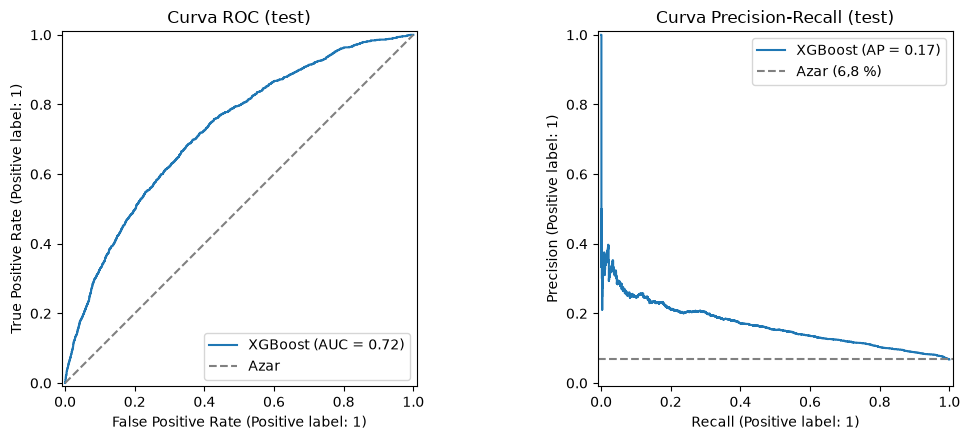

In [75]:
# Graficas de ROC y PR

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

y_arr = np.asarray(y_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

RocCurveDisplay.from_predictions(y_arr, proba_test, ax=ax[0], name="XGBoost")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ax[0].set_title("Curva ROC (test)")
ax[0].legend()

PrecisionRecallDisplay.from_predictions(y_arr, proba_test, ax=ax[1], name="XGBoost")
ax[1].axhline(y_arr.mean(), linestyle="--", color="gray", label="Azar (6,8 %)")
ax[1].set_title("Curva Precision-Recall (test)")
ax[1].legend()

plt.tight_layout()
plt.savefig("../docs/img/curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Nivel de riesgo

orden = np.argsort(-proba_test)          # de mas a menos riesgoso
y_orden = y_arr[orden]

for pct in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(y_orden) * pct)
    capturadas = y_orden[:k].sum() / y_arr.sum()
    print(f"Revisando el {pct:.0%} más riesgoso: capturás {capturadas:.1%} de las tardes")

Revisando el 5% más riesgoso: capturás 17.0% de las tardes
Revisando el 10% más riesgoso: capturás 29.9% de las tardes
Revisando el 20% más riesgoso: capturás 47.1% de las tardes
Revisando el 30% más riesgoso: capturás 60.0% de las tardes


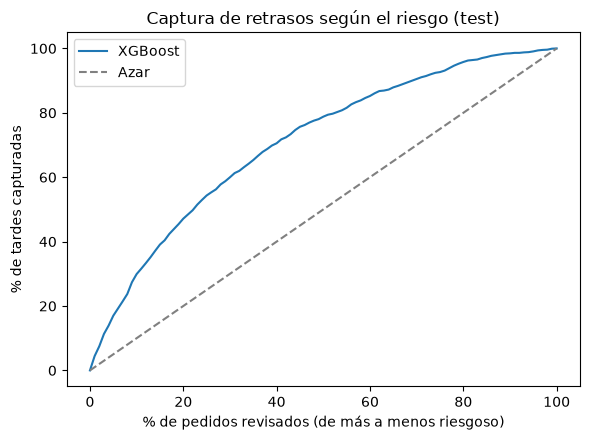

In [77]:
# Grafica del nivel de riesgo

pcts = np.linspace(0, 1, 101)
captura = [y_orden[:int(len(y_orden) * p)].sum() / y_arr.sum() for p in pcts]

plt.figure(figsize=(6, 4.5))
plt.plot(pcts * 100, np.array(captura) * 100, label="XGBoost")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Azar")
plt.xlabel("% de pedidos revisados (de más a menos riesgoso)")
plt.ylabel("% de tardes capturadas")
plt.title("Captura de retrasos según el riesgo (test)")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/img/captura_riesgo.png", dpi=150, bbox_inches="tight")
plt.show()

### Intervalos de confianza (bootstrap)

Para ver cuanto pueden variar las metricas finales, volvemos a sortear el conjunto de test 1.000 veces (con reemplazo) y calculamos las metricas en cada una. El intervalo de 95 % deja afuera el 2,5 % de los casos mas bajos y el 2,5 % de los mas altos. No se reentrena el modelo.

In [99]:
import joblib
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

modelo_final = joblib.load("../models/final_model.pkl")
proba = modelo_final.predict_proba(X_test)[:, 1]
y = np.asarray(y_test)


def captura_top(y, proba, nivel=0.10):
    k = int(len(y) * nivel)
    orden = np.argsort(-proba)
    return y[orden[:k]].sum() / y.sum()


rng = np.random.RandomState(42)
n = len(y)
resultados = {"roc_auc": [], "pr_auc": [], "captura_10": []}

for _ in range(1000):
    idx = rng.randint(0, n, n)
    yb, pb = y[idx], proba[idx]
    resultados["roc_auc"].append(roc_auc_score(yb, pb))
    resultados["pr_auc"].append(average_precision_score(yb, pb))
    resultados["captura_10"].append(captura_top(yb, pb))

for nombre, valores in resultados.items():
    bajo, alto = np.percentile(valores, [2.5, 97.5])
    print(f"{nombre}: {np.mean(valores):.3f}  IC 95 %: [{bajo:.3f}, {alto:.3f}]")

roc_auc: 0.726  IC 95 %: [0.711, 0.740]
pr_auc: 0.169  IC 95 %: [0.152, 0.186]
captura_10: 0.298  IC 95 %: [0.275, 0.320]


## Aprendizaje no supervisado: PCA y KMeans

Objetivo: ver si los pedidos se pueden agrupar segun su peso, su flete y los dias prometidos, y si algun grupo llega tarde mas seguido que otros.

Usamos PCA para resumir las 3 variables en 2 y KMeans para armar los grupos. No usamos la columna `tarde_dia` para armarlos: solo la miramos despues, para comparar.

In [ ]:
# PCA (entrenamiento NO SUPERVISADO)

import numpy as np
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# Definir el pipeline en orden
pre = ColumnTransformer([
    ("cola_larga", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p)),
        ("scaler", StandardScaler()),
    ]), ["peso_total_g", "flete_total"]),
    ("dias", Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
]), ["dias_prometidos"]),
])

pipe = Pipeline([("pre", pre), ("pca", PCA())])

# Ajustar (fit) SOLO con X_train para evitar data leakage
X_train_pca = pipe.fit_transform(X_train)

# Transformar X_test usando los parámetros aprendidos de X_train
X_test_pca = pipe.transform(X_test)




In [ ]:
pipe.named_steps["pca"].explained_variance_ratio_
# Esto quiere decir que las 3 variables no estan tan correlacionadas entre si. 

array([0.56361053, 0.30465429, 0.13173518])

In [86]:
# Voy a ver que variables pesan en cada componente.

import pandas as pd

pd.DataFrame(
    pipe.named_steps["pca"].components_[:2],
    columns=["peso_total_g", "flete_total", "dias_prometidos"],
    index=["PC1", "PC2"],
)

,peso_total_g,flete_total,dias_prometidos
PC1,0.578310,0.682561,0.446842
PC2,-0.574947,-0.047593,0.816805


In [ ]:
# Miro el % para ver si los componentes (de PC1) sirven para algo

df = pd.DataFrame(X_train_pca[:, :2], columns=["PC1", "PC2"])
df["tarde"] = y_train.values
df.groupby(pd.qcut(df["PC1"], 4))["tarde"].mean()

PC1
(-5.246, -0.841]    0.056183
(-0.841, -0.136]    0.071577
(-0.136, 0.742]     0.069866
(0.742, 9.7]        0.073287
Name: tarde, dtype: float64

In [88]:
df.groupby(pd.qcut(df["PC2"], 4))["tarde"].mean()

PC2
(-3.505, -0.63]     0.075619
(-0.63, -0.0307]    0.071462
(-0.0307, 0.593]    0.070810
(0.593, 11.975]     0.053022
Name: tarde, dtype: float64

In [89]:
# Clusters: si es mas alto el silhouette, mejor.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

X_pca2 = X_train_pca[:, :2]

# Muestra para que el silhouette no tarde una eternidad
rng = np.random.RandomState(42)
idx = rng.choice(len(X_pca2), size=10000, replace=False)
X_muestra = X_pca2[idx]

for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_muestra)
    print(k, round(silhouette_score(X_muestra, etiquetas), 3))

3 0.337
4 0.334
5 0.349


In [90]:
# El Kmeans no lo decide el silhouette por ende lo decide la segmentacion que cuente una mejor historia

for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_pca2)
    res = pd.DataFrame({"cluster": etiquetas, "tarde": y_train.values})
    print(f"\nk={k}")
    print(res.groupby("cluster")["tarde"].agg(pedidos="count", pct_tarde="mean").round(3))


k=3
         pedidos  pct_tarde
cluster                    
0          24496      0.061
1          33659      0.066
2          19021      0.080

k=4
         pedidos  pct_tarde
cluster                    
0          20621      0.059
1          23408      0.061
2          22377      0.078
3          10770      0.079

k=5
         pedidos  pct_tarde
cluster                    
0          10365      0.049
1          20686      0.079
2           8989      0.086
3          14099      0.053
4          23037      0.068


In [ ]:
# k=5 es el que mejor silhouete tiene pero tengo que respaldarla con estadistica

km = KMeans(n_clusters=5, random_state=42, n_init=10)
etq = km.fit_predict(X_pca2)

perfil = X_train[["peso_total_g", "flete_total", "dias_prometidos"]].copy()
perfil["cluster"] = etq
perfil["tarde"] = y_train.values

resumen = perfil.groupby("cluster").agg(
    pedidos=("tarde", "count"),
    pct_tarde=("tarde", "mean"),
    peso=("peso_total_g", "median"),
    flete=("flete_total", "median"),
    dias=("dias_prometidos", "median"),
)
resumen["ic95_mas_menos"] = 1.96 * np.sqrt(
    resumen["pct_tarde"] * (1 - resumen["pct_tarde"]) / resumen["pedidos"]
)
resumen.round(3)

# Se observa que el paquete pesado tiene casi el doble de tardes que el liviano. 

,pedidos,pct_tarde,peso,flete,dias,ic95_mas_menos
cluster,,,,,,
0,10365,0.049,751.0,24.62,35.0,0.004
1,20686,0.079,1825.0,18.44,21.0,0.004
2,8989,0.086,8350.0,46.68,26.0,0.006
3,14099,0.053,350.0,9.34,13.0,0.004
4,23037,0.068,308.0,15.46,25.0,0.003


In [92]:
# Ahora hago el TEST para ver si el patron se mantiene.

etq_test = km.predict(X_test_pca[:, :2])
res_test = pd.DataFrame({"cluster": etq_test, "tarde": y_test.values})
res_test.groupby("cluster")["tarde"].agg(pedidos="count", pct_tarde="mean").round(3)

,pedidos,pct_tarde
cluster,,
0,2618,0.059
1,5209,0.072
2,2211,0.080
3,3503,0.055
4,5753,0.071


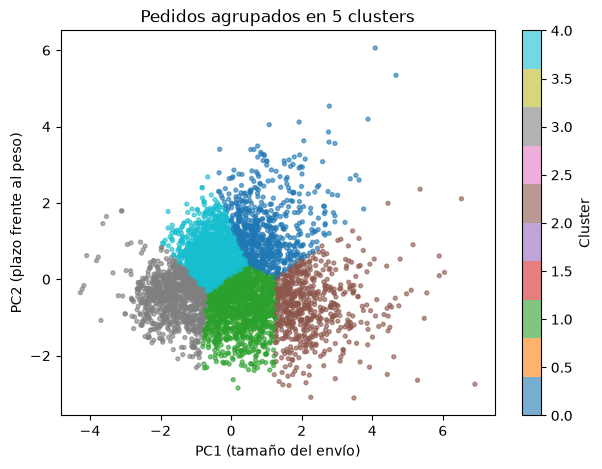

In [96]:
# Grafico de cluster en 2D

import matplotlib.pyplot as plt

# Muestra de 5.000 puntos para que el gráfico no quede cargado
rng = np.random.RandomState(42)
idx = rng.choice(len(X_pca2), size=5000, replace=False)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca2[idx, 0], X_pca2[idx, 1], c=etq[idx], cmap="tab10", s=8, alpha=0.6)
plt.xlabel("PC1 (tamaño del envío)")
plt.ylabel("PC2 (plazo frente al peso)")
plt.title("Pedidos agrupados en 5 clusters")
plt.colorbar(label="Cluster")
plt.savefig("../docs/img/clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

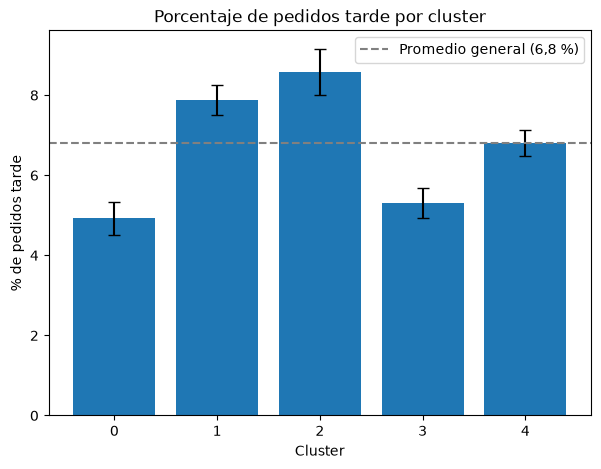

In [98]:
# Grafica 2: Porcentaje (%) de tarde por cluster

plt.figure(figsize=(7, 5))
plt.bar(resumen.index, resumen["pct_tarde"] * 100,
        yerr=resumen["ic95_mas_menos"] * 100, capsize=4)
plt.axhline(6.8, linestyle="--", color="gray", label="Promedio general (6,8 %)")
plt.xlabel("Cluster")
plt.ylabel("% de pedidos tarde")
plt.title("Porcentaje de pedidos tarde por cluster")
plt.legend()
plt.savefig("../docs/img/tarde_por_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusion

- Con 2 componentes se explica el 87 % de la informacion de las 3 variables.
- El primer componente representa el tamaño del envio (peso, flete y plazo) y el segundo compara el plazo con el peso.
- Armamos 5 grupos con KMeans (el silhouette es de 0,35, asi que los grupos no estan muy separados).
- En train, el porcentaje(%) de pedidos tarde va de 4,9 % a 8,6 % segun el grupo. En test va de 5,5 % a 8,0 %, o sea que la diferencia se achica.
- Los paquetes livianos con buen plazo llegan tarde menos veces, y los muy pesados mas. Pero la señal es debil: sirve para explorar, no para predecir. Para predecir usamos el modelo XGBoost.